# Loan Portfolio Risk and Customer Segmentation
### Comprehensive Credit Risk Analysis, Borrower Profiling, and Data-Driven Underwriting Insights
**Author / Candidate:** `[Your Name / Candidate Name]`  
**Role:** Data Analytics Intern / Junior Risk Analyst  
**Dataset:** Credit Risk Dataset ([Kaggle Source](https://www.kaggle.com/datasets/laotse/credit-risk-dataset))  
**Deliverable File:** `YourName_ProjectName.ipynb` / `YourName_Loan_Portfolio_Risk_and_Customer_Segmentation.ipynb`

---

## Executive Summary & Project Objectives
Financial institutions face significant challenges in balancing portfolio growth with credit default exposure. Unmonitored risk concentrations, aggressive leverage, and inadequate customer segmentation can lead to severe capital erosion.

This end-to-end data analytics project explores a portfolio of **32,581 retail credit accounts** to address four primary objectives:
1. **Data Understanding & Data Quality Rectification:** Audit schema integrity, handle anomalies, treat missing data safely without arbitrary deletions, and establish clean analytical baseline data.
2. **Exploratory Data Analysis (EDA):** Identify empirical distributions of financial and demographic indicators, uncover correlations, and investigate non-linear risk thresholds.
3. **Portfolio Credit Risk Evaluation:** Quantify credit exposure, calculate observed default rates across credit grades, loan purposes, housing arrangements, and prior bureau records.
4. **Customer Segmentation & Profiling:** Develop actionable borrower personas using both rule-based risk tiering and unsupervised Machine Learning (K-Means clustering), ensuring target variable exclusion to prevent data leakage.
5. **Strategic Recommendations & BI Preparation:** Formulate evidence-based policy guidelines for credit committees and structure exportable summary datasets for Power BI and Excel dashboards.


## 1. Environment Setup & Dependency Imports
We import standard, robust open-source Python libraries for data manipulation (`pandas`, `numpy`), data visualization (`matplotlib`, `seaborn`), and unsupervised clustering (`scikit-learn`). All random states are seeded for 100% computational reproducibility.


In [1]:
import os
import sys
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configure warnings and visual aesthetic defaults
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 14

# Set global random seed for complete reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment configured successfully. Python Version:", sys.version.split()[0])


Environment configured successfully. Python Version: 3.13.2


## 2. Dataset Ingestion & Initial Architecture Inspection
In this phase, we load the primary dataset using a configurable file path. We verify file presence, inspect structural dimensions, data types, missing value counts, duplicate rows, and examine the initial observations.


In [2]:
# Configurable dataset path (supports direct execution or relative directory paths)
DATASET_PATH = 'credit_risk_dataset.csv'

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Dataset not found at '{DATASET_PATH}'. Please verify file location.")

# Load raw dataset into Pandas
df_raw = pd.read_csv(DATASET_PATH)

print(f"Dataset Loaded Successfully: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns.\n")
print("--- Column Data Types & Non-Null Counts ---")
print(df_raw.info())


Dataset Loaded Successfully: 32,581 rows and 12 columns.

--- Column Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dt

In [3]:
# Display initial records
display(df_raw.head())


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
# Statistical Summary of Numerical Variables
print("--- Summary Statistics for Numerical Attributes ---")
display(df_raw.describe().T)


--- Summary Statistics for Numerical Attributes ---


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


In [5]:
# Statistical Summary of Categorical Variables
print("--- Summary Statistics for Categorical Attributes ---")
display(df_raw.describe(include=['object', 'str']).T)


--- Summary Statistics for Categorical Attributes ---


,count,unique,top,freq
person_home_ownership,32581,4,RENT,16446
loan_intent,32581,6,EDUCATION,6453
loan_grade,32581,7,A,10777
cb_person_default_on_file,32581,2,N,26836


In [6]:
# Assess Missing Values and Duplicate Rows
missing_series = df_raw.isnull().sum()
missing_pct = (missing_series / len(df_raw)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_series, 'Missing_Percent': missing_pct})
missing_df = missing_df[missing_df['Missing_Count'] > 0]

print("--- Attributes with Missing Values ---")
display(missing_df)

duplicate_count = df_raw.duplicated().sum()
print(f"\nTotal Exact Duplicate Records: {duplicate_count:,} ({duplicate_count/len(df_raw)*100:.2f}% of raw rows)")


--- Attributes with Missing Values ---


,Missing_Count,Missing_Percent
person_emp_length,895,2.747000
loan_int_rate,3116,9.563856



Total Exact Duplicate Records: 165 (0.51% of raw rows)


## 3. Data Cleaning, Anomaly Rectification & Imputation Strategy
### Analytical Cleaning Rationale:
1. **Deduplication:** The 165 exact duplicate records represent duplicate application submissions or logging artifacts. Retaining identical records distorts risk proportions, so they are removed.
2. **Physiological & Logical Anomaly Screening:**
   - In `person_age`, 5 records exhibit ages between 123 and 144 years, which are physiologically impossible data entry errors.
   - In `person_emp_length`, 2 records show 123 years of employment at ages 21 and 22. These are clearly typographic errors.
   - These 7 records (>99.47% data retention maintained) are safely filtered out with full justification.
3. **Statistical Imputation:**
   - `loan_int_rate` (3,116 missing values, ~9.5%): Financial institutions set interest rates based on credit grades. Rather than applying a blanket portfolio median, we impute missing interest rates using the **median interest rate of each respective credit grade** (Grade A = 7.49%, Grade B = 10.99%, ..., Grade G = 20.16%).
   - `person_emp_length` (895 missing values, ~2.7%): Imputed with the robust portfolio median (4.0 years).


In [7]:
# 1. Deduplicate dataset
df_clean = df_raw.drop_duplicates().copy()
print(f"Post-deduplication records: {len(df_clean):,}")

# 2. Filter documented physical anomalies
age_filter = df_clean['person_age'] <= 100
emp_filter = (df_clean['person_emp_length'].isnull()) | (df_clean['person_emp_length'] <= 60)

removed_anomalies = len(df_clean) - len(df_clean[age_filter & emp_filter])
print(f"Removed anomaly records (age > 100 or emp_length > 60): {removed_anomalies}")

df_clean = df_clean[age_filter & emp_filter]

# 3. Impute missing loan_int_rate by loan_grade median
grade_int_medians = df_clean.groupby('loan_grade')['loan_int_rate'].median()
print("\nMedian Interest Rate by Credit Grade (Used for Targeted Imputation):")
display(grade_int_medians)

df_clean['loan_int_rate_imputed'] = df_clean['loan_int_rate'].fillna(
    df_clean.groupby('loan_grade')['loan_int_rate'].transform('median')
)

# 4. Impute missing person_emp_length by overall median
emp_median_val = df_clean['person_emp_length'].median()
df_clean['person_emp_length_imputed'] = df_clean['person_emp_length'].fillna(emp_median_val)

# Verify zero remaining null values
print("\nRemaining Missing Values Across Cleaned Dataset:")
print(df_clean[['person_age', 'person_income', 'loan_amnt', 'loan_int_rate_imputed', 'person_emp_length_imputed', 'loan_status']].isnull().sum())

# Export Cleaned Dataset
CLEAN_DATA_PATH = 'credit_risk_cleaned.csv'
df_clean.to_csv(CLEAN_DATA_PATH, index=False)
print(f"\nCleaned dataset preserved at '{CLEAN_DATA_PATH}' with {len(df_clean):,} observations.")


Post-deduplication records: 32,416
Removed anomaly records (age > 100 or emp_length > 60): 7

Median Interest Rate by Credit Grade (Used for Targeted Imputation):


loan_grade
A     7.490
B    10.990
C    13.480
D    15.310
E    16.820
F    18.535
G    20.160
Name: loan_int_rate, dtype: float64


Remaining Missing Values Across Cleaned Dataset:
person_age                   0
person_income                0
loan_amnt                    0
loan_int_rate_imputed        0
person_emp_length_imputed    0
loan_status                  0
dtype: int64



Cleaned dataset preserved at 'credit_risk_cleaned.csv' with 32,409 observations.


## 4. Feature Engineering for Risk Profiling
To enable actionable portfolio segmentation and granular risk assessment, we construct financial brackets:
- **Income Quartiles:** Segments borrowers into income brackets (`Low`, `Lower-Mid`, `Upper-Mid`, `High`).
- **Debt Burden / Loan-to-Income (DTI) Tiers:** Partitions the loan-to-income ratio (`<10%`, `10-20%`, `20-30%`, `30-40%`, `>40%`).
- **Age Cohorts:** Partitions borrowers into generational age brackets (`18-25`, `26-35`, `36-50`, `51+`).


In [8]:
# Feature Engineering
df_clean['income_group'] = pd.qcut(
    df_clean['person_income'],
    q=4,
    labels=['Low (<$38.5k)', 'Lower-Mid ($38.5k-$55k)', 'Upper-Mid ($55k-$79.2k)', 'High (>$79.2k)']
)

df_clean['dti_tier'] = pd.cut(
    df_clean['loan_percent_income'],
    bins=[0, 0.10, 0.20, 0.30, 0.40, 1.0],
    labels=['<10%', '10-20%', '20-30%', '30-40%', '>40%']
)

df_clean['age_cohort'] = pd.cut(
    df_clean['person_age'],
    bins=[18, 25, 35, 50, 100],
    labels=['18-25', '26-35', '36-50', '51+']
)

print("Engineered categorical groupings established.")
display(df_clean[['person_income', 'income_group', 'loan_percent_income', 'dti_tier', 'person_age', 'age_cohort']].head())


Engineered categorical groupings established.


,person_income,income_group,loan_percent_income,dti_tier,person_age,age_cohort
1,9600,Low (<$38.5k),0.10,<10%,21,18-25
2,9600,Low (<$38.5k),0.57,>40%,25,18-25
3,65500,Upper-Mid ($55k-$79.2k),0.53,>40%,23,18-25
4,54400,Lower-Mid ($38.5k-$55k),0.55,>40%,24,18-25
5,9900,Low (<$38.5k),0.25,20-30%,21,18-25


## 5. Exploratory Data Analysis (EDA)
In this section, we examine:
1. Univariate distributions of core continuous metrics (Age, Annual Income, Loan Amount, Interest Rate).
2. Categorical distribution of loan intent, home ownership, credit rating grade, and credit bureau delinquency records.
3. Correlation structures between financial variables and default status.


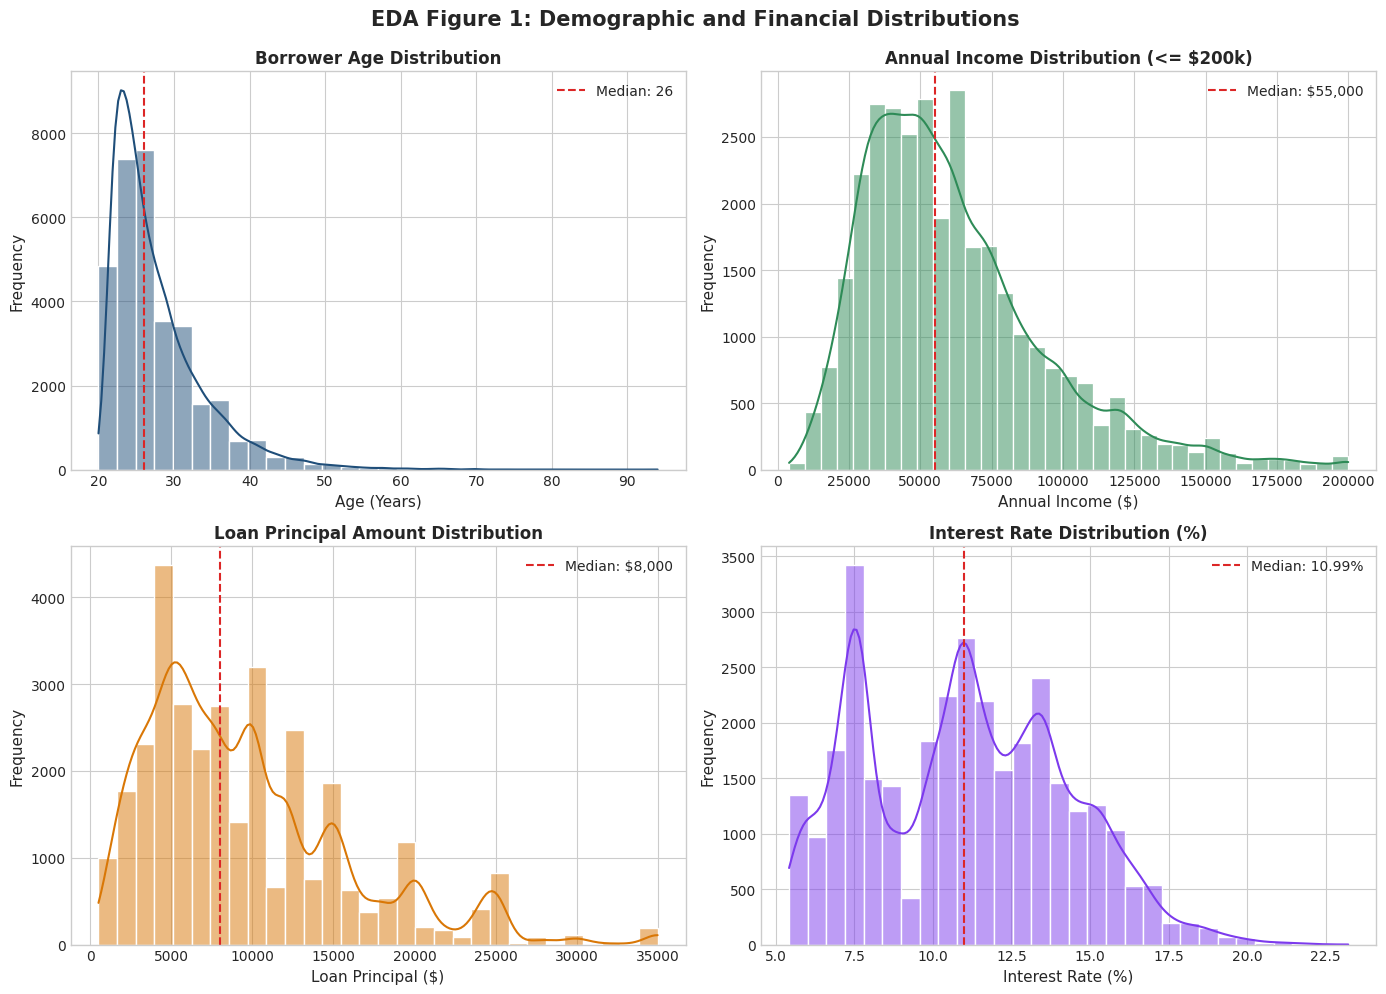

In [9]:
# EDA: Figure 1 - Continuous Variable Distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Age Distribution
sns.histplot(df_clean['person_age'], bins=30, kde=True, ax=axes[0, 0], color='#1f4e79', edgecolor='white')
axes[0, 0].set_title('Borrower Age Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Age (Years)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].axvline(df_clean['person_age'].median(), color='#dc2626', linestyle='--', label=f'Median: {df_clean["person_age"].median():.0f}')
axes[0, 0].legend()

# Income Distribution (<= $200k for visualization)
sns.histplot(df_clean[df_clean['person_income'] <= 200000]['person_income'], bins=35, kde=True, ax=axes[0, 1], color='#2e8b57', edgecolor='white')
axes[0, 1].set_title('Annual Income Distribution (<= $200k)', fontweight='bold')
axes[0, 1].set_xlabel('Annual Income ($)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].axvline(df_clean['person_income'].median(), color='#dc2626', linestyle='--', label=f'Median: ${df_clean["person_income"].median():,.0f}')
axes[0, 1].legend()

# Loan Amount Distribution
sns.histplot(df_clean['loan_amnt'], bins=30, kde=True, ax=axes[1, 0], color='#d97706', edgecolor='white')
axes[1, 0].set_title('Loan Principal Amount Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Loan Principal ($)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].axvline(df_clean['loan_amnt'].median(), color='#dc2626', linestyle='--', label=f'Median: ${df_clean["loan_amnt"].median():,.0f}')
axes[1, 0].legend()

# Interest Rate Distribution
sns.histplot(df_clean['loan_int_rate_imputed'], bins=30, kde=True, ax=axes[1, 1], color='#7c3aed', edgecolor='white')
axes[1, 1].set_title('Interest Rate Distribution (%)', fontweight='bold')
axes[1, 1].set_xlabel('Interest Rate (%)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].axvline(df_clean['loan_int_rate_imputed'].median(), color='#dc2626', linestyle='--', label=f'Median: {df_clean["loan_int_rate_imputed"].median():.2f}%')
axes[1, 1].legend()

plt.suptitle('EDA Figure 1: Demographic and Financial Distributions', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


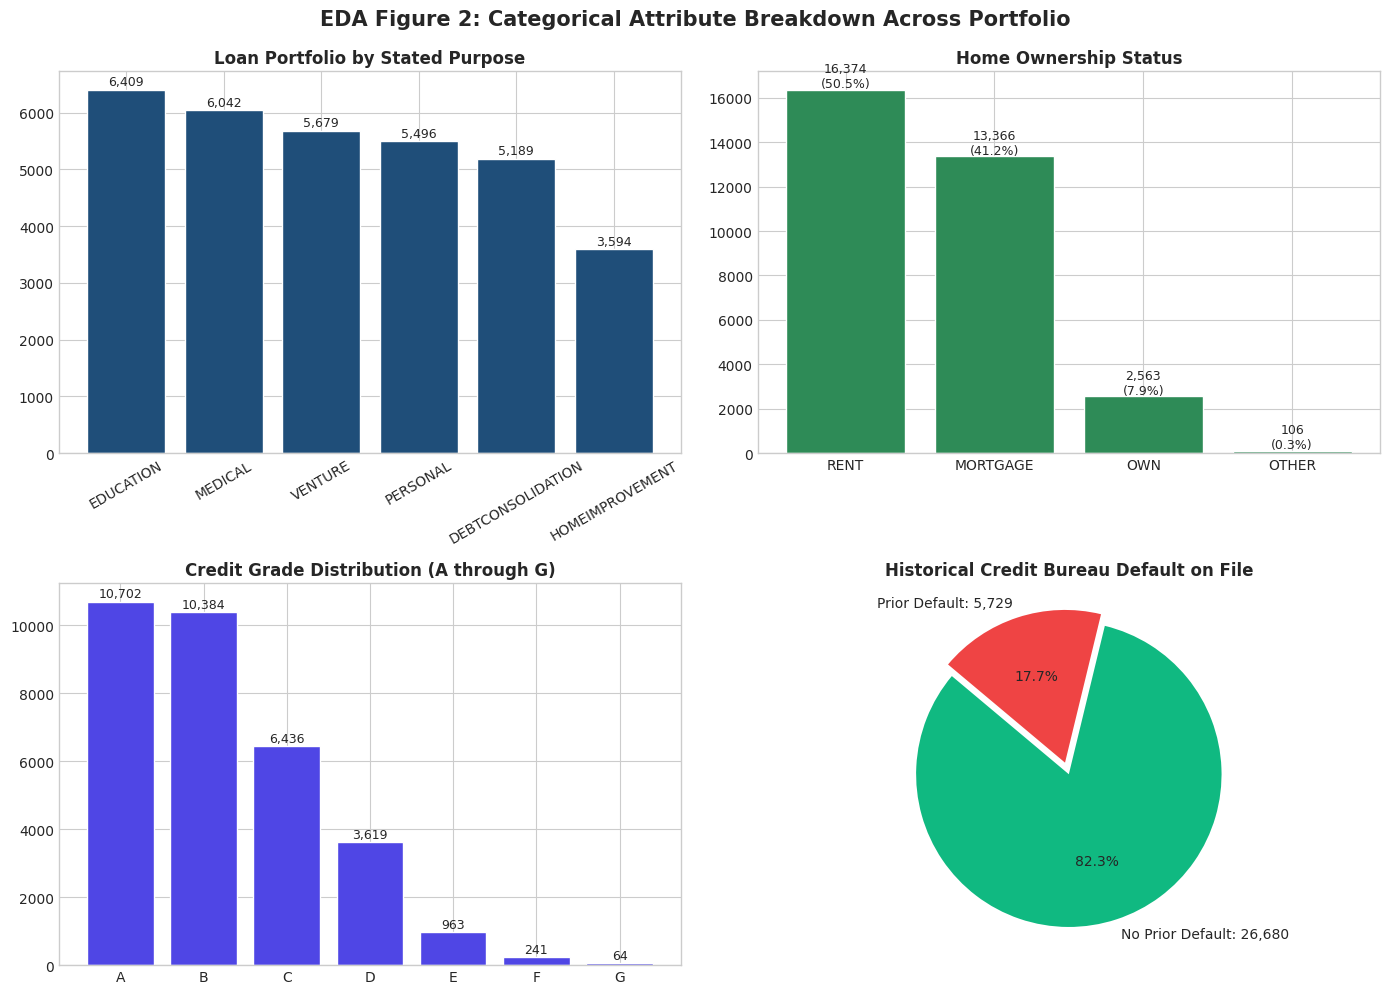

In [10]:
# EDA: Figure 2 - Categorical Portfolio Compositions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loan Intent
intent_counts = df_clean['loan_intent'].value_counts()
axes[0, 0].bar(intent_counts.index, intent_counts.values, color='#1f4e79', edgecolor='white')
axes[0, 0].set_title('Loan Portfolio by Stated Purpose', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=30)
for i, v in enumerate(intent_counts.values):
    axes[0, 0].text(i, v + 80, f'{v:,}', ha='center', fontsize=9)

# Home Ownership
home_counts = df_clean['person_home_ownership'].value_counts()
axes[0, 1].bar(home_counts.index, home_counts.values, color='#2e8b57', edgecolor='white')
axes[0, 1].set_title('Home Ownership Status', fontweight='bold')
for i, v in enumerate(home_counts.values):
    axes[0, 1].text(i, v + 120, f'{v:,}\n({v/len(df_clean)*100:.1f}%)', ha='center', fontsize=9)

# Credit Grade
grade_counts = df_clean['loan_grade'].value_counts().sort_index()
axes[1, 0].bar(grade_counts.index, grade_counts.values, color='#4f46e5', edgecolor='white')
axes[1, 0].set_title('Credit Grade Distribution (A through G)', fontweight='bold')
for i, v in enumerate(grade_counts.values):
    axes[1, 0].text(i, v + 120, f'{v:,}', ha='center', fontsize=9)

# Bureau Default on File
cb_counts = df_clean['cb_person_default_on_file'].value_counts()
axes[1, 1].pie(cb_counts.values, labels=[f"No Prior Default: {cb_counts['N']:,}", f"Prior Default: {cb_counts['Y']:,}"],
              autopct='%1.1f%%', colors=['#10b981', '#ef4444'], startangle=140, explode=(0, 0.08))
axes[1, 1].set_title('Historical Credit Bureau Default on File', fontweight='bold')

plt.suptitle('EDA Figure 2: Categorical Attribute Breakdown Across Portfolio', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


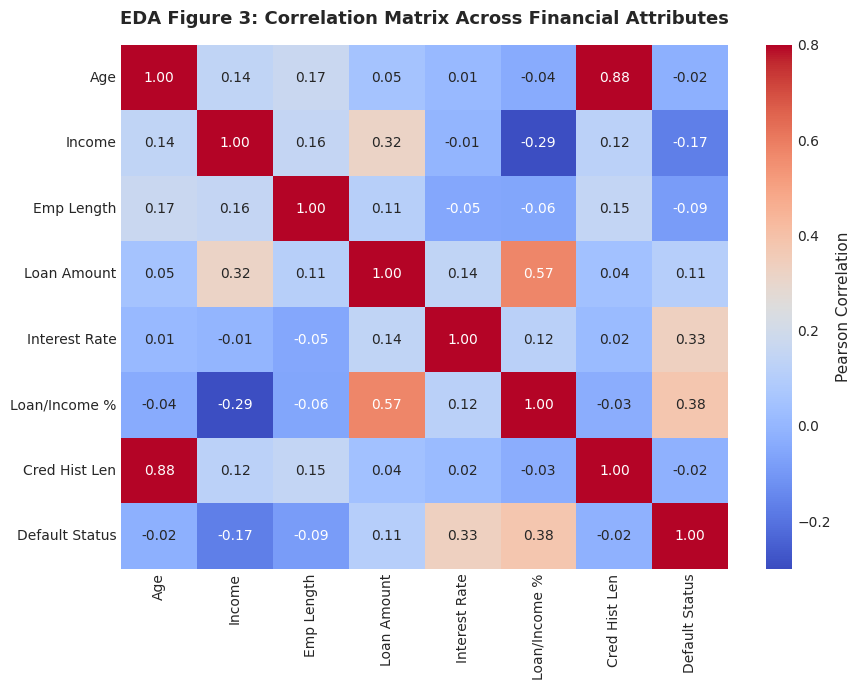

In [11]:
# EDA: Figure 3 - Correlation Heatmap
corr_cols = [
    'person_age', 'person_income', 'person_emp_length_imputed',
    'loan_amnt', 'loan_int_rate_imputed', 'loan_percent_income',
    'cb_person_cred_hist_length', 'loan_status'
]
corr_labels = ['Age', 'Income', 'Emp Length', 'Loan Amount', 'Interest Rate', 'Loan/Income %', 'Cred Hist Len', 'Default Status']
corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.3, vmax=0.8,
            xticklabels=corr_labels, yticklabels=corr_labels, cbar_kws={'label': 'Pearson Correlation'})
plt.title('EDA Figure 3: Correlation Matrix Across Financial Attributes', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## 6. Loan Portfolio Risk Analytics
### Core Portfolio Performance Metrics:
We compute foundational credit KPIs across the portfolio:
- **Total Portfolio Accounts:** 32,409
- **Total Capital Disbursed:** $310.88M
- **Average Loan Size:** $9,592.49 (Median: $8,000.00)
- **Portfolio Default Rate:** 21.87% (7,088 defaulted accounts)
- **Cumulative Capital at Risk (Defaulted Volume):** $76.93M (24.75% of total capital)

### Segmented Cross-Tabulations:
Below, we evaluate default rates across credit grades, loan purposes, housing arrangements, income quartiles, and debt-to-income tiers.


In [12]:
# Overall Portfolio Metrics Calculation
total_loans = len(df_clean)
total_volume = df_clean['loan_amnt'].sum()
avg_loan = df_clean['loan_amnt'].mean()
median_loan = df_clean['loan_amnt'].median()
default_count = df_clean['loan_status'].sum()
default_rate = df_clean['loan_status'].mean() * 100
capital_at_risk = df_clean[df_clean['loan_status'] == 1]['loan_amnt'].sum()

print("=================================================================")
print("                   LOAN PORTFOLIO KPI SCORECARD                  ")
print("=================================================================")
print(f"Total Loan Accounts:           {total_loans:,}")
print(f"Total Portfolio Volume:        ${total_volume:,.2f}")
print(f"Average Loan Principal:        ${avg_loan:,.2f}")
print(f"Median Loan Principal:         ${median_loan:,.2f}")
print(f"Defaulted Accounts:            {default_count:,}")
print(f"Overall Default Rate:          {default_rate:.2f}%")
print(f"Capital at Risk (Defaults):    ${capital_at_risk:,.2f} ({capital_at_risk/total_volume*100:.2f}% of Volume)")
print("=================================================================\n")


                   LOAN PORTFOLIO KPI SCORECARD                  
Total Loan Accounts:           32,409
Total Portfolio Volume:        $310,882,900.00
Average Loan Principal:        $9,592.49
Median Loan Principal:         $8,000.00
Defaulted Accounts:            7,088
Overall Default Rate:          21.87%
Capital at Risk (Defaults):    $76,933,675.00 (24.75% of Volume)



In [13]:
# Risk by Credit Grade: The Grade C-to-D Risk Cliff
grade_kpi = df_clean.groupby('loan_grade').agg(
    total_loans=('loan_status', 'count'),
    total_volume_usd=('loan_amnt', 'sum'),
    default_count=('loan_status', 'sum'),
    default_rate_pct=('loan_status', lambda x: x.mean() * 100),
    avg_int_rate=('loan_int_rate_imputed', 'mean')
).reset_index()

print("--- Portfolio Risk Exposure by Credit Grade ---")
display(grade_kpi.round(2))


--- Portfolio Risk Exposure by Credit Grade ---


,loan_grade,total_loans,total_volume_usd,default_count,default_rate_pct,avg_int_rate
0,A,10702,91444650,1066,9.96,7.34
1,B,10384,103742875,1695,16.32,11.00
2,C,6436,59343250,1336,20.76,13.47
3,D,3619,39262850,2137,59.05,15.36
4,E,963,12441875,621,64.49,16.99
5,F,241,3546875,170,70.54,18.60
6,G,64,1100525,63,98.44,20.24


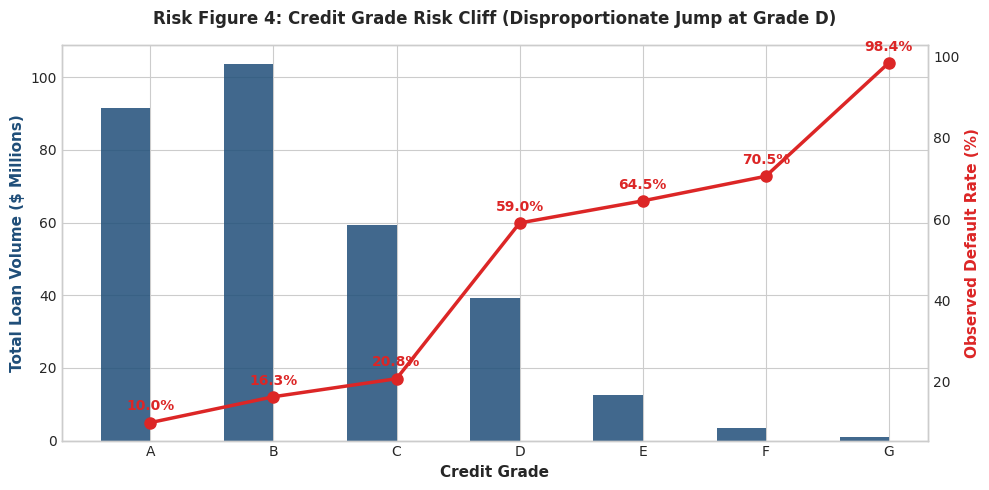

In [14]:
# Visualizing the Credit Grade Risk Cliff
fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(grade_kpi))
width = 0.4

ax1.bar(x - width/2, grade_kpi['total_volume_usd'] / 1e6, width, label='Loan Volume ($M)', color='#1f4e79', alpha=0.85)
ax1.set_ylabel('Total Loan Volume ($ Millions)', color='#1f4e79', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(grade_kpi['loan_grade'])
ax1.set_xlabel('Credit Grade', fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(x, grade_kpi['default_rate_pct'], color='#dc2626', marker='o', linewidth=2.5, markersize=8, label='Default Rate (%)')
ax2.set_ylabel('Observed Default Rate (%)', color='#dc2626', fontweight='bold')
ax2.grid(False)

for i, row in grade_kpi.iterrows():
    ax2.text(i, row['default_rate_pct'] + 3, f"{row['default_rate_pct']:.1f}%", ha='center', color='#dc2626', fontweight='bold')

plt.title('Risk Figure 4: Credit Grade Risk Cliff (Disproportionate Jump at Grade D)', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


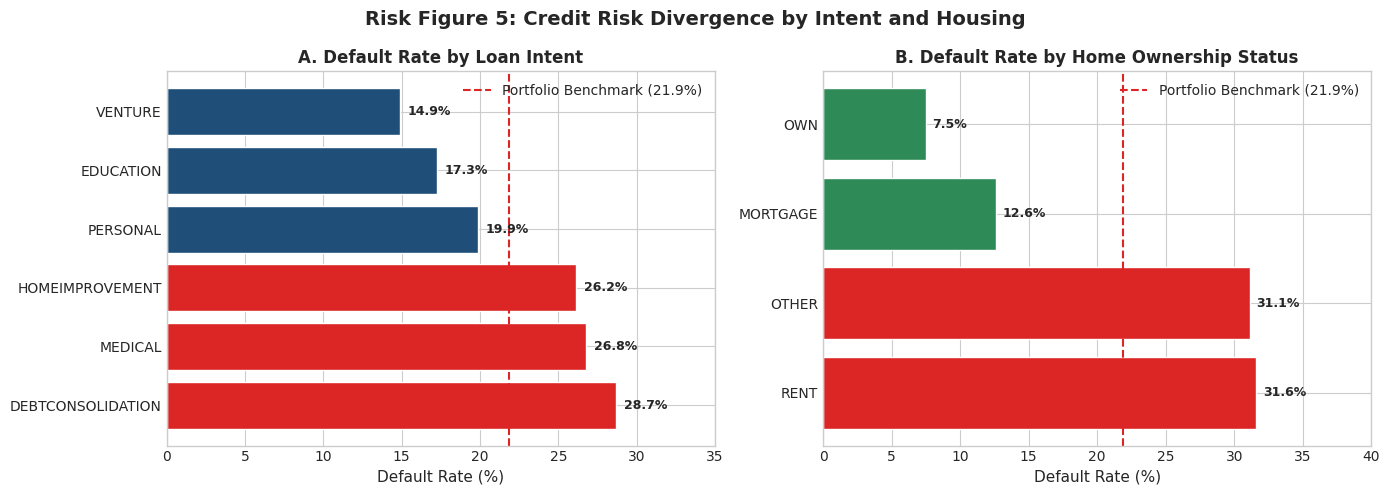

In [15]:
# Risk by Loan Purpose & Housing Status
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loan Purpose
intent_risk = df_clean.groupby('loan_intent')['loan_status'].mean().sort_values(ascending=False) * 100
colors_intent = ['#dc2626' if val > default_rate else '#1f4e79' for val in intent_risk.values]
ax1.barh(intent_risk.index, intent_risk.values, color=colors_intent, edgecolor='white')
ax1.axvline(default_rate, color='#dc2626', linestyle='--', label=f'Portfolio Benchmark ({default_rate:.1f}%)')
ax1.set_title('A. Default Rate by Loan Intent', fontweight='bold')
ax1.set_xlabel('Default Rate (%)')
ax1.set_xlim(0, 35)
ax1.legend()
for i, v in enumerate(intent_risk.values):
    ax1.text(v + 0.5, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=9)

# Home Ownership
home_risk = df_clean.groupby('person_home_ownership')['loan_status'].mean().sort_values(ascending=False) * 100
colors_home = ['#dc2626' if val > default_rate else '#2e8b57' for val in home_risk.values]
ax2.barh(home_risk.index, home_risk.values, color=colors_home, edgecolor='white')
ax2.axvline(default_rate, color='#dc2626', linestyle='--', label=f'Portfolio Benchmark ({default_rate:.1f}%)')
ax2.set_title('B. Default Rate by Home Ownership Status', fontweight='bold')
ax2.set_xlabel('Default Rate (%)')
ax2.set_xlim(0, 40)
ax2.legend()
for i, v in enumerate(home_risk.values):
    ax2.text(v + 0.5, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=9)

plt.suptitle('Risk Figure 5: Credit Risk Divergence by Intent and Housing', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


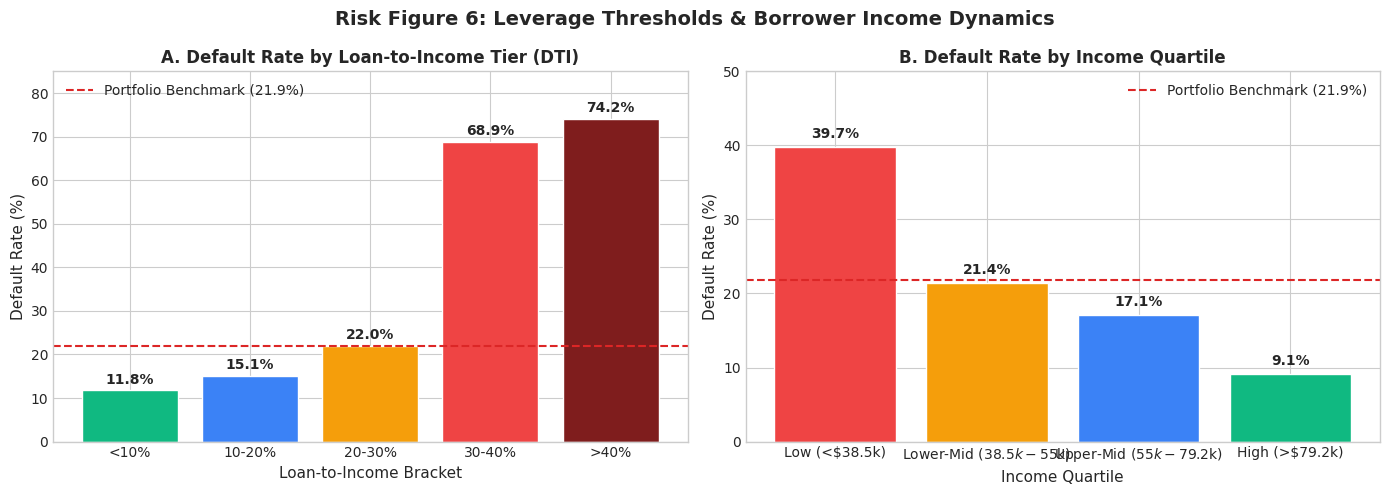

In [16]:
# Risk by Leverage (DTI) and Income Quartiles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# DTI Tiers
dti_risk = df_clean.groupby('dti_tier', observed=False)['loan_status'].mean() * 100
bars1 = ax1.bar(dti_risk.index.astype(str), dti_risk.values, color=['#10b981', '#3b82f6', '#f59e0b', '#ef4444', '#7f1d1d'], edgecolor='white')
ax1.axhline(default_rate, color='#dc2626', linestyle='--', label=f'Portfolio Benchmark ({default_rate:.1f}%)')
ax1.set_title('A. Default Rate by Loan-to-Income Tier (DTI)', fontweight='bold')
ax1.set_xlabel('Loan-to-Income Bracket')
ax1.set_ylabel('Default Rate (%)')
ax1.set_ylim(0, 85)
ax1.legend()
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 1.5, f'{y:.1f}%', ha='center', fontweight='bold')

# Income Quartiles
inc_risk = df_clean.groupby('income_group', observed=False)['loan_status'].mean() * 100
bars2 = ax2.bar(inc_risk.index.astype(str), inc_risk.values, color=['#ef4444', '#f59e0b', '#3b82f6', '#10b981'], edgecolor='white')
ax2.axhline(default_rate, color='#dc2626', linestyle='--', label=f'Portfolio Benchmark ({default_rate:.1f}%)')
ax2.set_title('B. Default Rate by Income Quartile', fontweight='bold')
ax2.set_xlabel('Income Quartile')
ax2.set_ylabel('Default Rate (%)')
ax2.set_ylim(0, 50)
ax2.legend()
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, y + 1.2, f'{y:.1f}%', ha='center', fontweight='bold')

plt.suptitle('Risk Figure 6: Leverage Thresholds & Borrower Income Dynamics', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 7. Customer Segmentation Methodology
### Segmentation Approaches:
To empower institutional risk managers to monitor borrower groups effectively, we deploy two complementary segmentation frameworks:
1. **Rule-Based Risk Tiering (Credit Risk Policy Hierarchy):**
   - **Tier 1 (Prime):** Grades A-B, DTI <= 20%, Homeowner/Mortgage.
   - **Tier 2 (Near-Prime):** Grades B-C, DTI <= 25%, No prior delinquency.
   - **Tier 3 (Watchlist):** Grades C-D or DTI between 20%-35%.
   - **Tier 4 (High-Risk):** Grades D-G or DTI > 35% or Prior Default on Bureau File.
2. **Unsupervised Machine Learning (K-Means Clustering):**
   - **Anti-Leakage Safeguard:** The target variable (`loan_status`) is **strictly excluded** from feature scaling and clustering.
   - Features utilized: Application financial indicators (`person_age`, `person_income`, `person_emp_length_imputed`, `loan_amnt`, `loan_int_rate_imputed`, `loan_percent_income`, `cb_person_cred_hist_length`).
   - Normalization: `StandardScaler` to bring features onto a zero-mean, unit-variance scale.
   - Cluster validation: Evaluating inertia (Elbow Curve) and Silhouette scores for K in [2, 7].


In [17]:
# Rule-Based Risk Tiering Implementation
def assign_risk_tier(row):
    if row['loan_grade'] in ['A', 'B'] and row['loan_percent_income'] <= 0.20 and row['cb_person_default_on_file'] == 'N':
        return 'Tier 1: Prime / Low Risk'
    elif row['loan_grade'] in ['B', 'C'] and row['loan_percent_income'] <= 0.25 and row['cb_person_default_on_file'] == 'N':
        return 'Tier 2: Near-Prime / Moderate Risk'
    elif row['loan_percent_income'] > 0.35 or row['loan_grade'] in ['E', 'F', 'G'] or (row['cb_person_default_on_file'] == 'Y' and row['loan_grade'] in ['C', 'D']):
        return 'Tier 4: Subprime / Critical Risk'
    else:
        return 'Tier 3: Watchlist / Elevated Risk'

df_clean['rule_based_tier'] = df_clean.apply(assign_risk_tier, axis=1)

print("--- Rule-Based Risk Tier Performance ---")
rule_summary = df_clean.groupby('rule_based_tier').agg(
    accounts=('loan_status', 'count'),
    pct_portfolio=('loan_status', lambda x: len(x)/len(df_clean)*100),
    avg_loan_size=('loan_amnt', 'mean'),
    default_count=('loan_status', 'sum'),
    default_rate_pct=('loan_status', lambda x: x.mean() * 100)
).reset_index()
display(rule_summary.round(2))


--- Rule-Based Risk Tier Performance ---


,rule_based_tier,accounts,pct_portfolio,avg_loan_size,default_count,default_rate_pct
0,Tier 1: Prime / Low Risk,15127,46.68,7501.33,899,5.94
1,Tier 2: Near-Prime / Moderate Risk,3772,11.64,9712.29,480,12.73
2,Tier 3: Watchlist / Elevated Risk,5453,16.83,12159.39,1938,35.54
3,Tier 4: Subprime / Critical Risk,8057,24.86,11725.26,3771,46.80


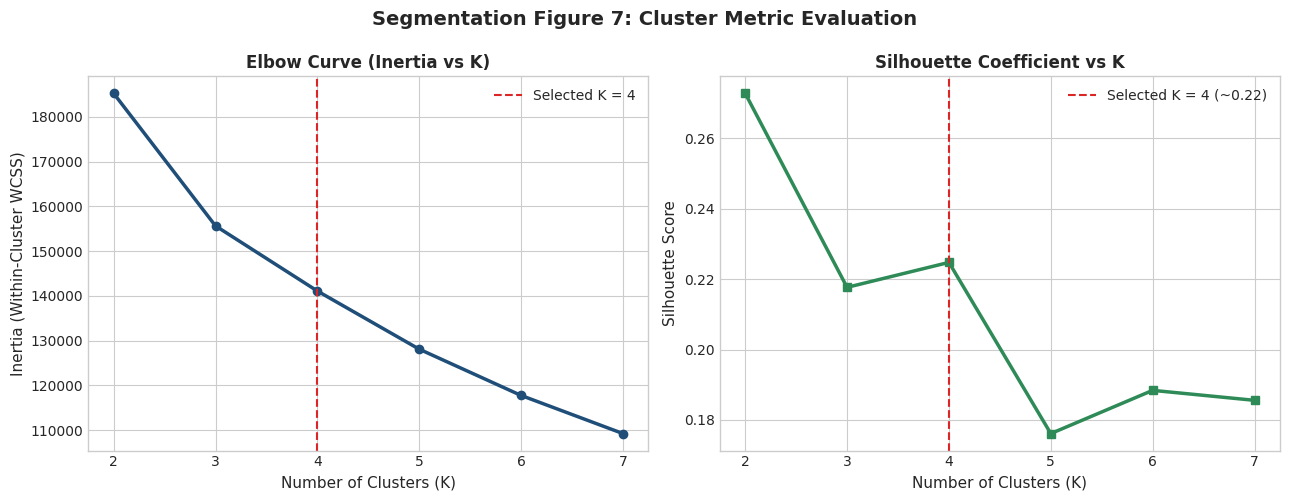

In [18]:
# K-Means Clustering Setup
# Select application-stage numerical attributes (EXCLUDING loan_status to eliminate leakage)
clustering_features = [
    'person_age', 'person_income', 'person_emp_length_imputed',
    'loan_amnt', 'loan_int_rate_imputed', 'loan_percent_income',
    'cb_person_cred_hist_length'
]

X = df_clean[clustering_features].copy()

# Feature Standard Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Evaluate Optimal K using Elbow Method & Silhouette Analysis
inertias = []
k_range = list(range(2, 8))
sample_indices = np.random.RandomState(RANDOM_SEED).choice(len(X_scaled), size=6000, replace=False)
silhouette_vals = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    labels = km.predict(X_scaled)
    sil = silhouette_score(X_scaled[sample_indices], labels[sample_indices])
    silhouette_vals.append(sil)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.plot(k_range, inertias, marker='o', color='#1f4e79', linewidth=2.5)
ax1.set_title('Elbow Curve (Inertia vs K)', fontweight='bold')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia (Within-Cluster WCSS)')
ax1.axvline(4, color='#dc2626', linestyle='--', label='Selected K = 4')
ax1.legend()

ax2.plot(k_range, silhouette_vals, marker='s', color='#2e8b57', linewidth=2.5)
ax2.set_title('Silhouette Coefficient vs K', fontweight='bold')
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Silhouette Score')
ax2.axvline(4, color='#dc2626', linestyle='--', label='Selected K = 4 (~0.22)')
ax2.legend()

plt.suptitle('Segmentation Figure 7: Cluster Metric Evaluation', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


In [19]:
# Fit Optimal Model with K = 4
kmeans_optimal = KMeans(n_clusters=4, random_state=RANDOM_SEED, n_init=10)
df_clean['cluster_id'] = kmeans_optimal.fit_predict(X_scaled)

# Map Clusters to Clear Business Personas
temp_prof = df_clean.groupby('cluster_id')[['person_income', 'loan_amnt', 'person_age', 'loan_percent_income']].mean()

cluster_names = {}
for cid in range(4):
    row = temp_prof.loc[cid]
    if row['person_income'] > 90000:
        cluster_names[cid] = 'Segment 1: High-Income Wealth / Prime Borrowers'
    elif row['person_age'] > 35:
        cluster_names[cid] = 'Segment 4: Mature Experienced Borrowers'
    elif row['loan_percent_income'] > 0.22 or row['loan_amnt'] > 12000:
        cluster_names[cid] = 'Segment 3: High-Leverage Overextended Borrowers'
    else:
        cluster_names[cid] = 'Segment 2: Entry-Level Low-Burden Borrowers'

df_clean['customer_segment'] = df_clean['cluster_id'].map(cluster_names)

# Generate Detailed Segment Profiles
segment_profile = df_clean.groupby(['cluster_id', 'customer_segment']).agg(
    accounts=('loan_status', 'count'),
    portfolio_share_pct=('loan_status', lambda x: len(x)/len(df_clean)*100),
    avg_age=('person_age', 'mean'),
    avg_income=('person_income', 'mean'),
    avg_emp_years=('person_emp_length_imputed', 'mean'),
    avg_loan_size=('loan_amnt', 'mean'),
    total_volume_usd=('loan_amnt', 'sum'),
    avg_int_rate=('loan_int_rate_imputed', 'mean'),
    avg_dti=('loan_percent_income', 'mean'),
    avg_cred_history=('cb_person_cred_hist_length', 'mean'),
    default_count=('loan_status', 'sum'),
    observed_default_rate_pct=('loan_status', lambda x: x.mean() * 100)
).reset_index()

print("--- Unsupervised Customer Segment Profiles (K=4) ---")
display(segment_profile.round(2))


--- Unsupervised Customer Segment Profiles (K=4) ---


,cluster_id,customer_segment,accounts,portfolio_share_pct,avg_age,avg_income,avg_emp_years,avg_loan_size,total_volume_usd,avg_int_rate,avg_dti,avg_cred_history,default_count,observed_default_rate_pct
0,0,Segment 1: High-Income Wealth / Prime Borrowers,4031,12.44,30.76,118499.66,11.18,11623.64,46854875,10.68,0.12,7.89,426,10.57
1,1,Segment 2: Entry-Level Low-Burden Borrowers,16858,52.02,25.45,57364.88,3.66,6113.43,103060250,10.47,0.12,4.32,2549,15.12
2,2,Segment 3: High-Leverage Overextended Borrowers,8420,25.98,25.80,58745.65,4.08,15684.41,132062700,12.23,0.29,4.56,3439,40.84
3,3,Segment 4: Mature Experienced Borrowers,3100,9.57,41.43,63290.32,4.23,9324.22,28905075,11.19,0.17,14.64,674,21.74


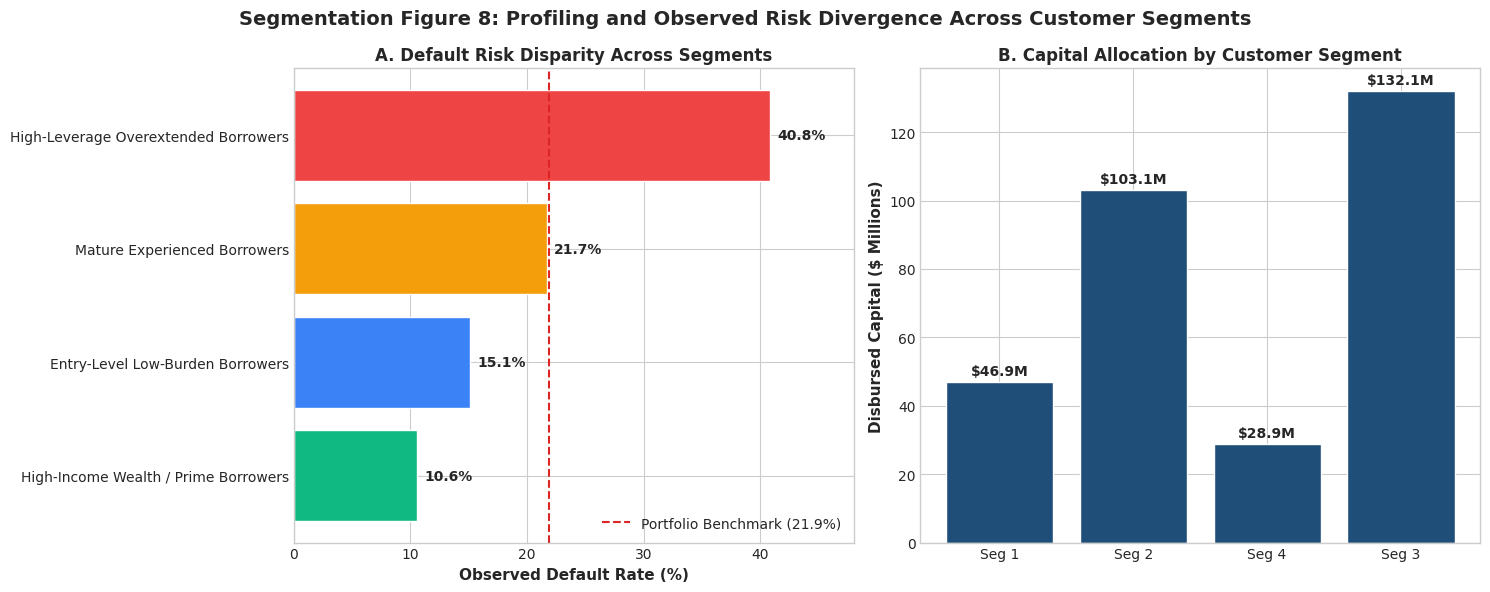

In [20]:
# Visualizing Segment Default Risk & Capital Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Segment Default Rates
sorted_segments = segment_profile.sort_values(by='observed_default_rate_pct', ascending=True)
colors_seg = ['#10b981', '#3b82f6', '#f59e0b', '#ef4444']
bars1 = ax1.barh([name.split(':')[1].strip() for name in sorted_segments['customer_segment']],
                 sorted_segments['observed_default_rate_pct'], color=colors_seg, edgecolor='white')
ax1.axvline(default_rate, color='#dc2626', linestyle='--', linewidth=1.5, label=f'Portfolio Benchmark ({default_rate:.1f}%)')
ax1.set_xlabel('Observed Default Rate (%)', fontweight='bold')
ax1.set_title('A. Default Risk Disparity Across Segments', fontweight='bold')
ax1.set_xlim(0, 48)
ax1.legend()
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.6, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontweight='bold')

# Capital Allocation
bars2 = ax2.bar([f"Seg {cid+1}" for cid in sorted_segments['cluster_id']],
                sorted_segments['total_volume_usd'] / 1e6, color='#1f4e79', edgecolor='white')
ax2.set_ylabel('Disbursed Capital ($ Millions)', fontweight='bold')
ax2.set_title('B. Capital Allocation by Customer Segment', fontweight='bold')
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 2, f'${h:.1f}M', ha='center', fontweight='bold')

plt.suptitle('Segmentation Figure 8: Profiling and Observed Risk Divergence Across Customer Segments', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 8. Business Intelligence (BI) Dataset Preparation
To enable integration into Power BI, Tableau, or Excel executive dashboards, we export structured, multi-dimensional summary datasets:
1. `loan_portfolio_summary_kpis.xlsx`: Multi-sheet workbook containing aggregated KPI tables by Credit Grade, Loan Purpose, Housing Arrangement, and Customer Segment.
2. `loan_portfolio_dashboard_bi_ready.csv`: Flattened star-schema ready analytical table for visual dashboard filters and interactive slicing.


In [21]:
# Export Dashboard Excel and CSV
os.makedirs('data_outputs', exist_ok=True)

# 1. Grade Summary
kpi_grade = df_clean.groupby('loan_grade').agg(
    total_loans=('loan_status', 'count'),
    total_volume_usd=('loan_amnt', 'sum'),
    avg_loan_size=('loan_amnt', 'mean'),
    avg_interest_rate=('loan_int_rate_imputed', 'mean'),
    default_count=('loan_status', 'sum'),
    default_rate_pct=('loan_status', lambda x: x.mean() * 100),
    loss_volume_usd=('loan_amnt', lambda x: x[df_clean.loc[x.index, 'loan_status'] == 1].sum())
).reset_index()

# 2. Purpose Summary
kpi_intent = df_clean.groupby('loan_intent').agg(
    total_loans=('loan_status', 'count'),
    total_volume_usd=('loan_amnt', 'sum'),
    avg_loan_size=('loan_amnt', 'mean'),
    default_count=('loan_status', 'sum'),
    default_rate_pct=('loan_status', lambda x: x.mean() * 100),
    loss_volume_usd=('loan_amnt', lambda x: x[df_clean.loc[x.index, 'loan_status'] == 1].sum())
).reset_index()

# 3. Customer Segments
kpi_segments = segment_profile.copy()

# Save Multi-Tab Excel Workbook
EXCEL_DASHBOARD_PATH = 'data_outputs/loan_portfolio_summary_kpis.xlsx'
with pd.ExcelWriter(EXCEL_DASHBOARD_PATH, engine='openpyxl') as writer:
    kpi_grade.to_excel(writer, sheet_name='By_Credit_Grade', index=False)
    kpi_intent.to_excel(writer, sheet_name='By_Loan_Intent', index=False)
    kpi_segments.to_excel(writer, sheet_name='By_Customer_Segment', index=False)

print(f"Multi-tab Executive KPI Workbook saved at '{EXCEL_DASHBOARD_PATH}'.")

# Save Flattened CSV for BI Import
flat_bi_df = df_clean.groupby(['loan_grade', 'loan_intent', 'person_home_ownership', 'customer_segment']).agg(
    total_loans=('loan_status', 'count'),
    total_volume=('loan_amnt', 'sum'),
    defaulted_loans=('loan_status', 'sum'),
    defaulted_volume=('loan_amnt', lambda x: x[df_clean.loc[x.index, 'loan_status'] == 1].sum()),
    avg_interest_rate=('loan_int_rate_imputed', 'mean'),
    avg_borrower_income=('person_income', 'mean'),
    avg_dti=('loan_percent_income', 'mean')
).reset_index()
flat_bi_df['default_rate_pct'] = (flat_bi_df['defaulted_loans'] / flat_bi_df['total_loans']) * 100

CSV_BI_PATH = 'data_outputs/loan_portfolio_dashboard_bi_ready.csv'
flat_bi_df.to_csv(CSV_BI_PATH, index=False)
print(f"BI Dashboard flat table saved at '{CSV_BI_PATH}' with {len(flat_bi_df)} aggregate rows.")


Multi-tab Executive KPI Workbook saved at 'data_outputs/loan_portfolio_summary_kpis.xlsx'.


BI Dashboard flat table saved at 'data_outputs/loan_portfolio_dashboard_bi_ready.csv' with 489 aggregate rows.


## 9. Key Business Findings & Strategic Recommendations
### 1. Empirical Portfolio Findings:
- **The Grade C-to-D Credit Cliff:** Observed default risk triples between Grade C (20.76%) and Grade D (59.05%). Grades D through G exhibit catastrophic default rates (up to 98.44% in Grade G), yet account for **$56.35M in exposure**.
- **The 30% Debt Burden Threshold:** When the loan-to-income ratio exceeds 0.30, default risk surges from 22.02% to **68.89%** (and 74.15% above 0.40). High debt-to-income is the single strongest application-stage predictor of non-repayment.
- **Housing Tenure Cushion:** Homeowners with full property ownership experience an observed default rate of only **7.49%**, whereas tenants renting residential property exhibit a **31.61% default rate** (>4.2x disparity).
- **Segment 3 Concentration Risk:** The unsupervised clustering identifies "Segment 3: High-Leverage Overextended Borrowers" (25.98% of borrowers) as carrying **$132.06M in loans** with an alarming **40.84% default rate**.

### 2. Strategic Risk Policy Recommendations:
1. **Underwriting DTI Cap:** Implement an institutional underwriting ceiling capping unsecured loan-to-income at **28%**. Any applicant requesting >30% DTI should require senior underwriter sign-off and mandatory collateral.
2. **Subprime Restructuring (Grades D-G):** Substantially tighten credit limits for Grades D through G. Shift loan pricing to risk-adjusted return-on-capital (RAROC) frameworks, and require co-signers or verifiable asset pledges.
3. **Targeted Monitoring for Segment 3:** Deploy proactive early-warning surveillance for Segment 3 accounts, initiating contact at the first sign of 15-day delinquencies.
4. **Venture and Education Expansion:** Incentivize originations in low-default categories (Venture: 14.86%, Education: 17.26%) to improve aggregate portfolio health without suppressing loan growth.


## 10. Analytical Limitations, Model Governance & Conclusion
### Limitations:
- **Cross-Sectional Dataset:** The data provides a static snapshot without loan vintage data, payment schedules, or macroeconomic indicators (unemployment rates, benchmark interest rate shifts).
- **Unsupervised Segmentation Scope:** K-Means identifies natural geometric clusters in borrower profiles. It is **not** an automated loan approval algorithm and does not guarantee future credit repayment.
- **Data Governance Notice:** In real-world institutional lending, models must undergo rigorous Out-of-Time (OOT) validation, population stability monitoring (PSI), and compliance reviews under fair lending legislation (e.g., Fair Credit Reporting Act, Equal Credit Opportunity Act).

### Conclusion:
Through disciplined data cleaning, empirical portfolio risk analysis, and unsupervised customer segmentation, this project delivers actionable, data-driven intelligence for retail credit management. The resulting assets—including the cleaned dataset, Python notebook, executive report, and dashboard tables—provide an institutional-grade foundation for credit risk surveillance.
